# ABCDario — manos + rostro + cuerpo + LSTM

Este Colab reemplaza el extractor anterior de 21 landmarks de una sola mano.

Cada frame contiene:
- 2 manos: 21 puntos por mano.
- Rostro relevante: ojos, cejas, nariz y boca.
- Parte superior del cuerpo: nariz, hombros, codos y muñecas.
- Indicadores de presencia de cada detector.

La secuencia completa se procesa con un LSTM para reconocer las letras.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os
import cv2
import numpy as np
import random
import json
from pathlib import Path

DATASET_DIR = "/content/drive/MyDrive/ABCDario"
OUTPUT_DIR = "/content/drive/MyDrive/ABCDario_Procesado"

SEQUENCE_LENGTH = 30

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

# Tu dataset actual tiene A-G.
# Cuando tengas todo el alfabeto:
# CLASSES = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")
CLASSES = list("ABCDEFG")

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Dataset:", DATASET_DIR)
print("Salida:", OUTPUT_DIR)
print("Clases:", CLASSES)


Dataset: /content/drive/MyDrive/ABCDario
Salida: /content/drive/MyDrive/ABCDario_Procesado
Clases: ['A', 'B', 'C', 'D', 'E', 'F', 'G']


In [ ]:
print("Verificando dataset...\n")

for letter in CLASSES:
    folder = os.path.join(DATASET_DIR, letter)

    if os.path.exists(folder):
        videos = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".mp4", ".avi", ".mov", ".mkv"))
        ]
        print(f"{letter}: {len(videos)} videos")
    else:
        print(f"{letter}: ❌ NO EXISTE")


Verificando dataset...

A: 33 videos
B: 32 videos
C: 34 videos
D: 34 videos
E: 34 videos
F: 34 videos
G: 34 videos


In [ ]:
!pip install -q mediapipe


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.9/37.9 MB 58.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 15.4 MB/s eta 0:00:00


In [ ]:
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

print("MediaPipe:", mp.__version__)


MediaPipe: 1.0.1


## Descargar los modelos

Se usan tres modelos de MediaPipe:
- Hands: hasta dos manos.
- Face Landmarker: rostro, pero solo guardaremos puntos relevantes.
- Pose Landmarker: parte superior del cuerpo.


In [ ]:
!wget -q -O hand_landmarker.task \
https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task

!wget -q -O face_landmarker.task \
https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task

!wget -q -O pose_landmarker.task \
https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_lite/float16/1/pose_landmarker_lite.task

print("✅ Modelos descargados")


✅ Modelos descargados


In [ ]:
# Puntos faciales relevantes:
# nariz, ojos, cejas y boca.
FACE_INDICES = [
    1,
    33, 133, 159, 145,
    263, 362, 386, 374,
    70, 63, 105,
    300, 293, 334,
    61, 291, 13, 14, 78, 308
]

# Pose: nariz, hombros, codos y muñecas.
POSE_INDICES = [0, 11, 12, 13, 14, 15, 16]

NUM_HAND_FEATURES = 2 * 21 * 3
NUM_FACE_FEATURES = len(FACE_INDICES) * 3
NUM_POSE_FEATURES = len(POSE_INDICES) * 3
NUM_PRESENCE_FEATURES = 4

FEATURES_PER_FRAME = (
    NUM_HAND_FEATURES
    + NUM_FACE_FEATURES
    + NUM_POSE_FEATURES
    + NUM_PRESENCE_FEATURES
)

print("Manos:", NUM_HAND_FEATURES)
print("Rostro:", NUM_FACE_FEATURES)
print("Pose:", NUM_POSE_FEATURES)
print("Presence:", NUM_PRESENCE_FEATURES)
print("TOTAL:", FEATURES_PER_FRAME)


Manos: 126
Rostro: 63
Pose: 21
Presence: 4
TOTAL: 214


In [ ]:
def create_hand_detector():
    base_options = python.BaseOptions(
        model_asset_path="hand_landmarker.task"
    )

    options = vision.HandLandmarkerOptions(
        base_options=base_options,
        running_mode=vision.RunningMode.VIDEO,
        num_hands=2,
        min_hand_detection_confidence=0.5,
        min_hand_presence_confidence=0.5,
        min_tracking_confidence=0.5
    )

    return vision.HandLandmarker.create_from_options(options)


def create_face_detector():
    base_options = python.BaseOptions(
        model_asset_path="face_landmarker.task"
    )

    options = vision.FaceLandmarkerOptions(
        base_options=base_options,
        running_mode=vision.RunningMode.VIDEO,
        num_faces=1,
        min_face_detection_confidence=0.5,
        min_face_presence_confidence=0.5,
        min_tracking_confidence=0.5
    )

    return vision.FaceLandmarker.create_from_options(options)


def create_pose_detector():
    base_options = python.BaseOptions(
        model_asset_path="pose_landmarker.task"
    )

    options = vision.PoseLandmarkerOptions(
        base_options=base_options,
        running_mode=vision.RunningMode.VIDEO,
        num_poses=1,
        min_pose_detection_confidence=0.5,
        min_pose_presence_confidence=0.5,
        min_tracking_confidence=0.5
    )

    return vision.PoseLandmarker.create_from_options(options)


## Normalización

Las coordenadas se normalizan usando el centro de los hombros como referencia y el ancho de hombros como escala. Así el modelo aprende relaciones como "mano respecto del ojo/hombro" y depende menos de la distancia a la cámara.

Si no se detectan los hombros, se usa una referencia de respaldo.


In [ ]:
def normalize_points(points, center, scale):
    if points is None or len(points) == 0:
        return np.zeros((0, 3), dtype=np.float32)

    return (points - center) / scale


def get_pose_reference(pose_landmarks):
    if pose_landmarks is None or len(pose_landmarks) < 13:
        return np.array([0.5, 0.5, 0.0], dtype=np.float32), 1.0

    left = np.array([
        pose_landmarks[11].x,
        pose_landmarks[11].y,
        pose_landmarks[11].z
    ], dtype=np.float32)

    right = np.array([
        pose_landmarks[12].x,
        pose_landmarks[12].y,
        pose_landmarks[12].z
    ], dtype=np.float32)

    center = (left + right) / 2.0
    scale = np.linalg.norm(left[:2] - right[:2])

    if scale < 1e-4:
        scale = 1.0

    return center, scale


In [ ]:
def extract_features_from_frame(
    frame,
    timestamp_ms,
    hand_detector,
    face_detector,
    pose_detector
):
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=frame_rgb
    )

    hand_result = hand_detector.detect_for_video(
        mp_image, timestamp_ms
    )
    face_result = face_detector.detect_for_video(
        mp_image, timestamp_ms
    )
    pose_result = pose_detector.detect_for_video(
        mp_image, timestamp_ms
    )

    pose_landmarks = (
        pose_result.pose_landmarks[0]
        if pose_result.pose_landmarks
        else None
    )

    center, scale = get_pose_reference(pose_landmarks)

    # ---------------- MANOS ----------------
    hand_features = np.zeros((2, 21, 3), dtype=np.float32)
    hand_presence = [0.0, 0.0]

    if hand_result.hand_landmarks:
        for i, hand in enumerate(hand_result.hand_landmarks[:2]):
            points = np.array(
                [[p.x, p.y, p.z] for p in hand],
                dtype=np.float32
            )
            points = normalize_points(points, center, scale)

            handedness = "Right"
            if hand_result.handedness and i < len(hand_result.handedness):
                handedness = hand_result.handedness[i][0].category_name

            slot = 0 if handedness.lower() == "left" else 1
            hand_features[slot] = points
            hand_presence[slot] = 1.0

    # ---------------- ROSTRO ----------------
    face_features = np.zeros(
        (len(FACE_INDICES), 3),
        dtype=np.float32
    )
    face_presence = 0.0

    if face_result.face_landmarks:
        face = face_result.face_landmarks[0]

        points = np.array(
            [[face[i].x, face[i].y, face[i].z] for i in FACE_INDICES],
            dtype=np.float32
        )
        face_features = normalize_points(points, center, scale)
        face_presence = 1.0

    # ---------------- POSE ----------------
    pose_features = np.zeros(
        (len(POSE_INDICES), 3),
        dtype=np.float32
    )
    pose_presence = 0.0

    if pose_landmarks:
        points = np.array(
            [[pose_landmarks[i].x,
              pose_landmarks[i].y,
              pose_landmarks[i].z]
             for i in POSE_INDICES],
            dtype=np.float32
        )
        pose_features = normalize_points(points, center, scale)
        pose_presence = 1.0

    vector = np.concatenate([
        hand_features.reshape(-1),
        face_features.reshape(-1),
        pose_features.reshape(-1),
        np.array([
            hand_presence[0],
            hand_presence[1],
            face_presence,
            pose_presence
        ], dtype=np.float32)
    ])

    return vector.astype(np.float32)


In [ ]:
def extract_sequence_from_video(
    video_path,
    sequence_length=30,
    verbose=False
):
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        print(f"❌ No se pudo abrir: {video_path}")
        return None

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)

    if total_frames <= 0:
        cap.release()
        return None

    if fps <= 0:
        fps = 30.0

    # Un detector nuevo por video evita el problema de timestamps
    # acumulados entre videos.
    hand_detector = create_hand_detector()
    face_detector = create_face_detector()
    pose_detector = create_pose_detector()

    frame_indices = np.linspace(
        0, total_frames - 1, sequence_length
    ).astype(int)

    sequence = []
    current_frame = 0
    target_index = 0
    previous_timestamp = -1

    try:
        while target_index < sequence_length:
            ret, frame = cap.read()

            if not ret:
                break

            if current_frame == frame_indices[target_index]:
                timestamp_ms = int(current_frame * 1000 / fps)

                if timestamp_ms <= previous_timestamp:
                    timestamp_ms = previous_timestamp + 1

                previous_timestamp = timestamp_ms

                features = extract_features_from_frame(
                    frame,
                    timestamp_ms,
                    hand_detector,
                    face_detector,
                    pose_detector
                )

                if len(features) != FEATURES_PER_FRAME:
                    print("❌ Dimensión incorrecta:", len(features))
                    return None

                sequence.append(features)
                target_index += 1

            current_frame += 1

    finally:
        cap.release()
        hand_detector.close()
        face_detector.close()
        pose_detector.close()

    if len(sequence) != sequence_length:
        if verbose:
            print(
                f"⚠️ Video incompleto: "
                f"{os.path.basename(video_path)} "
                f"({len(sequence)}/{sequence_length})"
            )
        return None

    return np.asarray(sequence, dtype=np.float32)


## Probar un solo video

Antes de procesar todo el Drive, ejecutá esta celda.

Esperamos:

`Shape: (30, 214)`

Los 214 valores son:
- 126 manos
- 63 rostro
- 21 pose
- 4 indicadores de presencia.


In [ ]:
test_video = "/content/drive/MyDrive/ABCDario/A/a_01.mp4"

sequence = extract_sequence_from_video(
    test_video,
    SEQUENCE_LENGTH,
    verbose=True
)

if sequence is not None:
    print("✅ Video procesado")
    print("Shape:", sequence.shape)
    print("Esperado:", (SEQUENCE_LENGTH, FEATURES_PER_FRAME))
else:
    print("❌ No se pudo procesar")


✅ Video procesado
Shape: (30, 214)
Esperado: (30, 214)


Mano izquierda: False
Mano derecha: True
Rostro: True
Pose: True
Features: 214


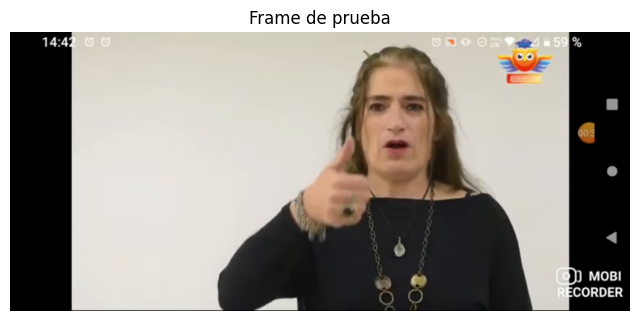

In [ ]:
def inspect_frame(video_path, frame_number=0):
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        print("❌ Video inválido")
        return

    frame_number = min(frame_number, total_frames - 1)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    ret, frame = cap.read()
    cap.release()

    if not ret:
        print("❌ No se pudo leer el frame")
        return

    hand_detector = create_hand_detector()
    face_detector = create_face_detector()
    pose_detector = create_pose_detector()

    try:
        features = extract_features_from_frame(
            frame, 0,
            hand_detector,
            face_detector,
            pose_detector
        )
    finally:
        hand_detector.close()
        face_detector.close()
        pose_detector.close()

    presence = features[-4:]

    print("Mano izquierda:", bool(presence[0]))
    print("Mano derecha:", bool(presence[1]))
    print("Rostro:", bool(presence[2]))
    print("Pose:", bool(presence[3]))
    print("Features:", len(features))

    import matplotlib.pyplot as plt
    plt.figure(figsize=(8, 6))
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title("Frame de prueba")
    plt.show()


inspect_frame(test_video, 0)


## Train / Validation / Test

La etiqueta se obtiene de la carpeta: `A/a_01.mp4` pertenece a la clase A. El nombre `a_01` no es necesario para etiquetar.

La división actual es 70/15/15 por letra.


In [ ]:
def split_dataset():
    splits = {
        "train": {},
        "validation": {},
        "test": {}
    }

    for letter in CLASSES:
        folder = os.path.join(DATASET_DIR, letter)

        if not os.path.exists(folder):
            print(f"⚠️ Falta carpeta: {letter}")
            continue

        videos = sorted([
            os.path.join(folder, f)
            for f in os.listdir(folder)
            if f.lower().endswith(
                (".mp4", ".avi", ".mov", ".mkv")
            )
        ])

        random.shuffle(videos)

        total = len(videos)
        train_end = int(total * TRAIN_RATIO)
        val_end = train_end + int(total * VAL_RATIO)

        splits["train"][letter] = videos[:train_end]
        splits["validation"][letter] = videos[train_end:val_end]
        splits["test"][letter] = videos[val_end:]

        print(
            f"{letter}: "
            f"Train={len(splits['train'][letter])} | "
            f"Val={len(splits['validation'][letter])} | "
            f"Test={len(splits['test'][letter])}"
        )

    return splits


splits = split_dataset()


A: Train=23 | Val=4 | Test=6
B: Train=22 | Val=4 | Test=6
C: Train=23 | Val=5 | Test=6
D: Train=23 | Val=5 | Test=6
E: Train=23 | Val=5 | Test=6
F: Train=23 | Val=5 | Test=6
G: Train=23 | Val=5 | Test=6


In [ ]:
for split in ["train", "validation", "test"]:
    for letter in CLASSES:
        os.makedirs(
            os.path.join(
                OUTPUT_DIR,
                "landmarks",
                split,
                letter
            ),
            exist_ok=True
        )

print("✅ Carpetas de landmarks creadas")


✅ Carpetas de landmarks creadas


In [ ]:
def process_split(split_name, split_data):
    print(f"\n{'='*60}")
    print(f"PROCESANDO: {split_name.upper()}")
    print(f"{'='*60}")

    total = success = failed = 0
    per_letter = {}

    for letter in CLASSES:
        videos = split_data.get(letter, [])

        output_folder = os.path.join(
            OUTPUT_DIR, "landmarks", split_name, letter
        )
        os.makedirs(output_folder, exist_ok=True)

        valid = failed_letter = 0

        for video_path in videos:
            total += 1
            filename = Path(video_path).stem
            output_path = os.path.join(
                output_folder,
                filename + ".npy"
            )

            if os.path.exists(output_path):
                try:
                    existing = np.load(output_path, mmap_mode="r")
                    if existing.shape == (
                        SEQUENCE_LENGTH,
                        FEATURES_PER_FRAME
                    ):
                        success += 1
                        valid += 1
                        continue
                except Exception:
                    pass

            sequence = extract_sequence_from_video(
                video_path,
                SEQUENCE_LENGTH,
                verbose=True
            )

            if sequence is None:
                failed += 1
                failed_letter += 1
                print("❌ Falló:", video_path)
                continue

            np.save(output_path, sequence)
            success += 1
            valid += 1

        per_letter[letter] = {
            "total": len(videos),
            "valid": valid,
            "failed": failed_letter
        }

        print(
            f"{letter}: válidos={valid} | "
            f"fallidos={failed_letter}"
        )

    print("\nResultado:")
    print("Total:", total)
    print("Correctos:", success)
    print("Fallidos:", failed)

    return per_letter


train_stats = process_split("train", splits["train"])
val_stats = process_split("validation", splits["validation"])
test_stats = process_split("test", splits["test"])



PROCESANDO: TRAIN
⚠️ Video incompleto: a_16.mp4 (1/30)
❌ Falló: /content/drive/MyDrive/ABCDario/A/a_16.mp4
⚠️ Video incompleto: a_07.mp4 (1/30)
❌ Falló: /content/drive/MyDrive/ABCDario/A/a_07.mp4
⚠️ Video incompleto: a_03.mp4 (1/30)
❌ Falló: /content/drive/MyDrive/ABCDario/A/a_03.mp4
A: válidos=20 | fallidos=3
⚠️ Video incompleto: b_17.mp4 (1/30)
❌ Falló: /content/drive/MyDrive/ABCDario/B/b_17.mp4
B: válidos=21 | fallidos=1
C: válidos=23 | fallidos=0
⚠️ Video incompleto: d_07.mp4 (1/30)
❌ Falló: /content/drive/MyDrive/ABCDario/D/d_07.mp4
⚠️ Video incompleto: d_04.mp4 (1/30)
❌ Falló: /content/drive/MyDrive/ABCDario/D/d_04.mp4
D: válidos=21 | fallidos=2
⚠️ Video incompleto: e_07.mp4 (1/30)
❌ Falló: /content/drive/MyDrive/ABCDario/E/e_07.mp4
⚠️ Video incompleto: e_16.mp4 (1/30)
❌ Falló: /content/drive/MyDrive/ABCDario/E/e_16.mp4
E: válidos=21 | fallidos=2
⚠️ Video incompleto: f_07.mp4 (1/30)
❌ Falló: /content/drive/MyDrive/ABCDario/F/f_07.mp4
F: válidos=22 | fallidos=1
⚠️ Video incomplet

## Cargar los landmarks

A diferencia del notebook original, ahora esperamos `(30, 214)` en lugar de `(30, 63)`.

No usamos `Masking`: las detecciones parciales pueden faltar en un frame intermedio, y los cuatro indicadores de presencia informan al modelo de qué partes fueron detectadas.


In [ ]:
def load_landmark_dataset(split):
    X = []
    y = []

    split_dir = os.path.join(
        OUTPUT_DIR, "landmarks", split
    )

    for label, letter in enumerate(CLASSES):
        folder = os.path.join(split_dir, letter)

        if not os.path.exists(folder):
            continue

        files = sorted([
            f for f in os.listdir(folder)
            if f.endswith(".npy")
        ])

        for file in files:
            path = os.path.join(folder, file)

            try:
                sequence = np.load(path)
            except Exception:
                continue

            if sequence.shape != (
                SEQUENCE_LENGTH,
                FEATURES_PER_FRAME
            ):
                continue

            X.append(sequence)
            y.append(label)

    if not X:
        return (
            np.empty(
                (0, SEQUENCE_LENGTH, FEATURES_PER_FRAME),
                dtype=np.float32
            ),
            np.empty((0,), dtype=np.int32)
        )

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.int32)
    )


X_train, y_train = load_landmark_dataset("train")
X_val, y_val = load_landmark_dataset("validation")
X_test, y_test = load_landmark_dataset("test")

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Train: (168, 30, 214)
Validation: (42, 30, 214)
Test: (58, 30, 214)


## Crear el LSTM

La arquitectura recibe una secuencia de 30 frames y todas las características multimodales de cada frame.


In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

NUM_CLASSES = len(CLASSES)

model = Sequential([
    Input(
        shape=(SEQUENCE_LENGTH, FEATURES_PER_FRAME)
    ),

    LSTM(
        128,
        return_sequences=True
    ),

    Dropout(0.30),

    LSTM(64),

    Dropout(0.30),

    Dense(
        64,
        activation="relu"
    ),

    Dropout(0.20),

    Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 128)        │       175,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 229,639 (897.03 KB)

 Trainable params: 229,639 (897.03 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
checkpoint_path = os.path.join(
    OUTPUT_DIR,
    "modelo_alfabeto_multimodal_lstm.keras"
)

callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=12,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6
    ),

    ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        save_best_only=True
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=60,
    batch_size=16,
    callbacks=callbacks,
    shuffle=True
)


Epoch 1/60
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 94ms/step - accuracy: 0.1845 - loss: 1.9447 - val_accuracy: 0.2619 - val_loss: 1.8811 - learning_rate: 0.0010
Epoch 2/60
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.3571 - loss: 1.8159 - val_accuracy: 0.3095 - val_loss: 1.8102 - learning_rate: 0.0010
Epoch 3/60
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3036 - loss: 1.7466 - val_accuracy: 0.2619 - val_loss: 1.7328 - learning_rate: 0.0010
Epoch 4/60
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3690 - loss: 1.6393 - val_accuracy: 0.3095 - val_loss: 1.6273 - learning_rate: 0.0010
Epoch 5/60
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.3810 - loss: 1.5230 - val_accuracy: 0.3571 - val_loss: 1.5735 - learning_rate: 0.0010
Epoch 6/60
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4464 - loss: 1.4048 - val_accuracy: 0.3095 - val_loss: 1.5503 - learning_rate: 0.0010
Epoch 7/60
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4345 - loss: 1.4339 - val_acc

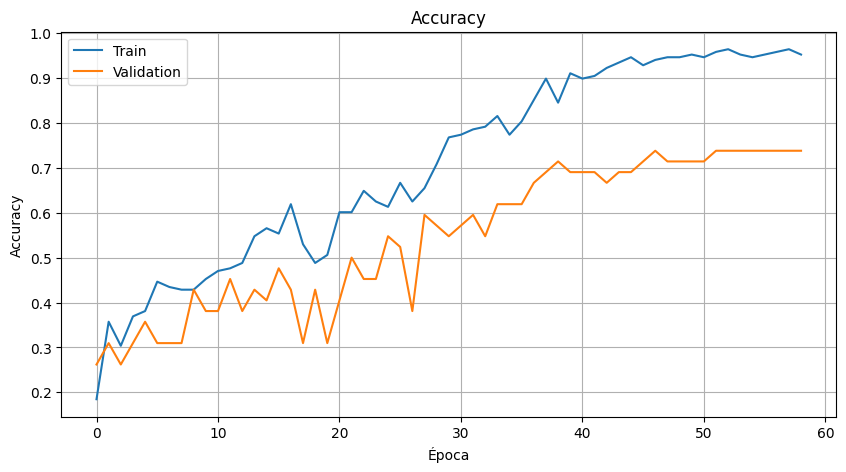

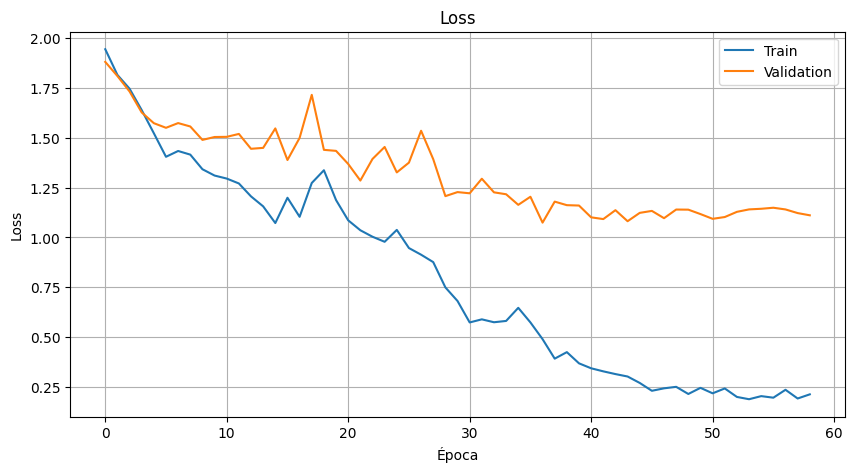

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print()
print("================================")
print(f"Accuracy TEST: {test_accuracy * 100:.2f}%")
print("================================")


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7241 - loss: 0.9998

Accuracy TEST: 72.41%


              precision    recall  f1-score   support

           A       0.70      0.78      0.74         9
           B       0.58      1.00      0.74         7
           C       0.56      0.62      0.59         8
           D       0.67      0.29      0.40         7
           E       0.83      0.62      0.71         8
           F       1.00      0.80      0.89        10
           G       0.80      0.89      0.84         9

    accuracy                           0.72        58
   macro avg       0.73      0.71      0.70        58
weighted avg       0.75      0.72      0.72        58



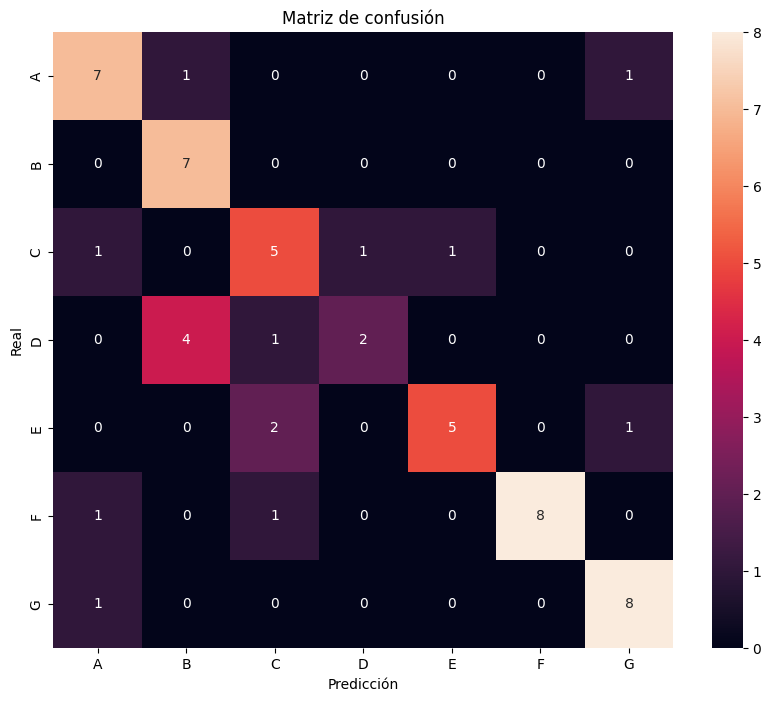

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

predictions = model.predict(X_test, verbose=0)
y_pred = np.argmax(predictions, axis=1)

print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASSES,
        zero_division=0
    )
)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión")
plt.show()


In [ ]:
def predict_video(video_path, top_k=5):
    sequence = extract_sequence_from_video(
        video_path,
        SEQUENCE_LENGTH,
        verbose=True
    )

    if sequence is None:
        print("❌ No se pudo procesar el video.")
        return None

    X = np.expand_dims(sequence, axis=0)
    prediction = model.predict(X, verbose=0)[0]

    top_indices = np.argsort(prediction)[-top_k:][::-1]

    print("\n================================")
    print("PREDICCIÓN")
    print("================================")

    for rank, index in enumerate(top_indices, 1):
        print(
            f"{rank}. {CLASSES[index]} "
            f"→ {prediction[index] * 100:.2f}%"
        )

    return CLASSES[top_indices[0]], prediction


# Ejemplo:
# predict_video("/content/drive/MyDrive/ABCDario/A/a_01.mp4")


In [ ]:
config = {
    "classes": CLASSES,
    "sequence_length": SEQUENCE_LENGTH,
    "features_per_frame": FEATURES_PER_FRAME,
    "face_indices": FACE_INDICES,
    "pose_indices": POSE_INDICES,
    "hand_features": NUM_HAND_FEATURES,
    "face_features": NUM_FACE_FEATURES,
    "pose_features": NUM_POSE_FEATURES,
    "presence_features": NUM_PRESENCE_FEATURES,
    "normalization": "shoulder_center_and_shoulder_width"
}

config_path = os.path.join(
    OUTPUT_DIR,
    "modelo_config.json"
)

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(
        config,
        f,
        indent=2,
        ensure_ascii=False
    )

print("✅ Configuración:", config_path)
print("✅ Modelo:", checkpoint_path)


✅ Configuración: /content/drive/MyDrive/ABCDario_Procesado/modelo_config.json
✅ Modelo: /content/drive/MyDrive/ABCDario_Procesado/modelo_alfabeto_multimodal_lstm.keras
